In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-rvvtz0q3
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-rvvtz0q3
  Resolved https://github.com/openai/CLIP.git to commit ded190a052fdf4585bd685cee5bc96e0310d2c93
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369490 sha256=c0ce418b5c1567aa3545a4a566ece469e948ce835a895bce8605880a49b274fc
  Stored in directory: /tmp/pip-ephem-wheel-cache-j2a32nr8/wheels/35/3e/df/3d24cbfb3b6a06f17a2bfd7d1138900d4365d9028aa8f6e92f
Successfully built clip


In [3]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from PIL import Image
from pathlib import Path
from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional, Union
import gc
from diffusers import StableDiffusionPipeline, DDIMScheduler
from IPython.display import display
import clip
from PIL import Image
import gc

print("✓ Imports loaded")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


✓ Imports loaded


In [4]:
print("Loading CLIP model for similarity scoring...")

clip_device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model, clip_preprocess = clip.load(
    "ViT-B/32",
    device=clip_device,
    jit=False
)

clip_model.eval()

print("✓ CLIP loaded")


Loading CLIP model for similarity scoring...


100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 161MiB/s]


✓ CLIP loaded


In [5]:
# ===================== CELL 2: Config =====================
@dataclass
class RunConfig:
    prompt: str = "a yellow car and a blue bird"
    token_indices: List[int] = None
    seeds: List[int] = field(default_factory=lambda: [42])
    output_path: Path = Path('./outputs')
    n_inference_steps: int = 50
    guidance_scale: float = 7.5
    max_iter_to_alter: int = 25
    attention_res: int = 16
    run_standard_sd: bool = False
    thresholds: Dict[int, float] = field(default_factory=lambda: {0: 0.05, 10: 0.5, 20: 0.8})
    scale_factor: int = 20
    scale_range: Tuple[float, float] = (1.0, 0.5)
    smooth_attentions: bool = True
    sigma: float = 0.5
    kernel_size: int = 3
    height: int = 512
    width: int = 512

    def __post_init__(self):
        self.output_path.mkdir(exist_ok=True, parents=True)

print("✓ Config created")

# ===================== CELL 3: Gaussian Smoothing =====================
class GaussianSmoothing(nn.Module):
    def __init__(self, channels, kernel_size, sigma, dim=2):
        super().__init__()
        if isinstance(kernel_size, (int, float)):
            kernel_size = [kernel_size] * dim
        if isinstance(sigma, (int, float)):
            sigma = [sigma] * dim
        
        kernel = 1.0
        meshgrids = torch.meshgrid(
            [torch.arange(size, dtype=torch.float32) for size in kernel_size],
            indexing="ij"
        )
        for size, std, mgrid in zip(kernel_size, sigma, meshgrids):
            mean = (size - 1) / 2
            kernel *= (1 / (std * math.sqrt(2 * math.pi))) * torch.exp(-((mgrid - mean) ** 2) / (2 * std ** 2))
        
        kernel = kernel / torch.sum(kernel)
        kernel = kernel.view(1, 1, *kernel.size())
        kernel = kernel.repeat(channels, *[1] * (kernel.dim() - 1))
        
        self.register_buffer('weight', kernel)
        self.groups = channels
        self.conv = F.conv2d

    def forward(self, input):
        return self.conv(input, weight=self.weight.to(input.device).to(input.dtype), groups=self.groups, padding='same')

print("✓ GaussianSmoothing created")

# ===================== CELL 4: Attention Store =====================
class AttentionStore:
    def __init__(self, attention_res=16):
        self.attention_res = attention_res
        self.reset()
    
    def reset(self):
        self.step_store = []
        self.attention_store = []
        self.curr_step_index = 0
    
    def __call__(self, attn_map, is_cross: bool, place_in_unet: str):
        if is_cross:
            # Only store attention at target resolution
            if attn_map.shape[1] == self.attention_res ** 2:
                # Keep on GPU but detach to save memory (we'll handle gradients separately)
                self.step_store.append(attn_map.detach())
    
    def between_steps(self):
        if len(self.step_store) > 0:
            self.attention_store.append(self.step_store[:])
            self.step_store = []
        self.curr_step_index += 1
    
    def get_average_attention(self):
        if len(self.step_store) == 0:
            return None
        # Average over all stored attention maps
        attention = torch.stack(self.step_store).mean(0)
        return attention

print("✓ AttentionStore created")

# ===================== CELL 5: Attention Processor =====================
class AttendExciteAttnProcessor:
    def __init__(self, attnstore: AttentionStore, place_in_unet: str):
        self.attnstore = attnstore
        self.place_in_unet = place_in_unet

    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, **kwargs):
        batch_size = hidden_states.shape[0]
        is_cross = encoder_hidden_states is not None
        
        if is_cross:
            encoder_hidden_states_input = encoder_hidden_states
        else:
            encoder_hidden_states_input = hidden_states
        
        query = attn.to_q(hidden_states)
        key = attn.to_k(encoder_hidden_states_input)
        value = attn.to_v(encoder_hidden_states_input)
        
        query = attn.head_to_batch_dim(query)
        key = attn.head_to_batch_dim(key)
        value = attn.head_to_batch_dim(value)
        
        attention_probs = attn.get_attention_scores(query, key, attention_mask)
        
        # Store conditional part only (second half for CFG)
        if is_cross:
            if attention_probs.shape[0] // batch_size == 2:
                attn_to_store = attention_probs[attention_probs.shape[0] // 2:]
            else:
                attn_to_store = attention_probs
            self.attnstore(attn_to_store, is_cross, self.place_in_unet)
        
        hidden_states = torch.bmm(attention_probs, value)
        hidden_states = attn.batch_to_head_dim(hidden_states)
        hidden_states = attn.to_out[0](hidden_states)
        hidden_states = attn.to_out[1](hidden_states)
        
        return hidden_states

def register_attention_control(model, controller: AttentionStore):
    attn_procs = {}
    for name in model.unet.attn_processors.keys():
        if name.startswith("mid_block"):
            place = "mid"
        elif name.startswith("up_blocks"):
            place = "up"
        elif name.startswith("down_blocks"):
            place = "down"
        else:
            place = "other"
        
        attn_procs[name] = AttendExciteAttnProcessor(controller, place)
    
    model.unet.set_attn_processor(attn_procs)
    print(f"  ✓ Registered {len(attn_procs)} attention processors")

print("✓ Attention control created")

# ===================== CELL 6: Attend-and-Excite Pipeline =====================
class AttendAndExcitePipeline(StableDiffusionPipeline):
    
    def _compute_max_attention_per_index(self, attention_maps, indices_to_alter, smooth_attentions, 
                                        sigma, kernel_size, attention_res, device):
        """Compute max attention for each token index."""
        # attention_maps shape: (batch*heads, spatial, tokens)
        attention_for_text = attention_maps[:, :, 1:-1]  # Remove BOS/EOS tokens
        attention_for_text *= 100
        attention_for_text = torch.nn.functional.softmax(attention_for_text, dim=-1)

        # Indices are offset by 1 (due to BOS token)
        indices = [index - 1 for index in indices_to_alter]
        
        # Extract attention for specified indices
        max_attentions = []
        for index in indices:
            if index < attention_for_text.shape[-1]:
                # Get attention map for this token: (batch*heads, spatial)
                attn_map = attention_for_text[:, :, index]
                
                # Reshape to 2D: (batch*heads, H, W)
                num_pixels = attn_map.shape[0]
                attn_map_2d = attn_map.reshape(num_pixels, attention_res, attention_res)
                
                # Apply Gaussian smoothing if requested
                if smooth_attentions:
                    # Add channel dimension for conv: (batch*heads, 1, H, W)
                    attn_map_2d = attn_map_2d.unsqueeze(1)
                    smoothing = GaussianSmoothing(channels=1, kernel_size=kernel_size, sigma=sigma).to(device)
                    attn_map_2d = smoothing(attn_map_2d)
                    attn_map_2d = attn_map_2d.squeeze(1)
                
                # Get max attention across all spatial locations
                max_attn = attn_map_2d.max()
                max_attentions.append(max_attn)
        
        if len(max_attentions) == 0:
            return torch.tensor([0.0], device=device)
        
        return torch.stack(max_attentions)

    def _aggregate_and_get_max_attention_per_token(self, attention_store, indices_to_alter, 
                                                     smooth_attentions, sigma, kernel_size, 
                                                     attention_res, device):
        """Aggregate attention and get max per token."""
        attention_maps = attention_store.get_average_attention()
        
        if attention_maps is None:
            return torch.tensor([0.0] * len(indices_to_alter), device=device)
        
        max_attention = self._compute_max_attention_per_index(
            attention_maps=attention_maps,
            indices_to_alter=indices_to_alter,
            smooth_attentions=smooth_attentions,
            sigma=sigma,
            kernel_size=kernel_size,
            attention_res=attention_res,
            device=device
        )
        
        return max_attention

    def _compute_loss(self, max_attention_per_index):
        """Compute attention loss."""
        losses = [max(0.0, 1.0 - curr_max.item()) for curr_max in max_attention_per_index]
        loss = max(losses) if losses else 0.0
        return loss

    def _update_latent(self, latents, loss, step_size):
        """Update latents with gradient descent."""
        if loss > 0:
            grad = torch.autograd.grad(loss, latents, retain_graph=False)[0]
            latents = latents - step_size * grad
        return latents

    def _perform_iterative_refinement_step(self, latents, indices_to_alter, loss, threshold, 
                                          step_size, t, attention_store, smooth_attentions, 
                                          sigma, kernel_size, attention_res, max_refinement_steps, 
                                          device, text_embeddings):
        """Iteratively refine latents to maximize attention."""
        iteration = 0
        target_loss = max(0.0, 1.0 - threshold)
        
        while loss > target_loss and iteration < max_refinement_steps:
            # Enable gradients for latents
            latents = latents.clone().detach().requires_grad_(True)
            
            # Forward pass through UNet to get new attention maps
            _ = self.unet(latents, t, encoder_hidden_states=text_embeddings).sample
            
            # Get updated attention
            max_attention = self._aggregate_and_get_max_attention_per_token(
                attention_store=attention_store,
                indices_to_alter=indices_to_alter,
                smooth_attentions=smooth_attentions,
                sigma=sigma,
                kernel_size=kernel_size,
                attention_res=attention_res,
                device=device
            )
            
            # Compute loss (this will be a scalar we can differentiate)
            loss_tensor = torch.clamp(1.0 - max_attention, min=0.0).max()
            loss = loss_tensor.item()
            
            if loss > target_loss and loss_tensor.requires_grad:
                # Update latents
                latents = self._update_latent(latents, loss_tensor, step_size)
            
            attention_store.reset()
            iteration += 1
        
        return latents.detach(), loss

    @torch.no_grad()
    def __call__(
        self,
        prompt: Union[str, List[str]],
        attention_store: AttentionStore,
        indices_to_alter: List[int],
        height: int = 512,
        width: int = 512,
        num_inference_steps: int = 50,
        guidance_scale: float = 7.5,
        generator: Optional[torch.Generator] = None,
        run_standard_sd: bool = False,
        max_iter_to_alter: int = 25,
        thresholds: dict = None,
        scale_factor: float = 20.0,
        scale_range: Tuple[float, float] = (1.0, 0.5),
        smooth_attentions: bool = True,
        sigma: float = 0.5,
        kernel_size: int = 3,
        attention_res: int = 16,
        **kwargs
    ):
        device = self._execution_device
        
        if thresholds is None:
            thresholds = {0: 0.05, 10: 0.5, 20: 0.8}
        
        if run_standard_sd:
            return super().__call__(
                prompt=prompt,
                height=height,
                width=width,
                num_inference_steps=num_inference_steps,
                guidance_scale=guidance_scale,
                generator=generator
            )
        
        # Encode prompt
        text_input = self.tokenizer(
            prompt,
            padding="max_length",
            max_length=self.tokenizer.model_max_length,
            truncation=True,
            return_tensors="pt"
        )
        
        text_embeddings = self.text_encoder(text_input.input_ids.to(device))[0]
        
        # Unconditional embeddings
        uncond_input = self.tokenizer(
            [""],
            padding="max_length",
            max_length=text_input.input_ids.shape[-1],
            return_tensors="pt"
        )
        uncond_embeddings = self.text_encoder(uncond_input.input_ids.to(device))[0]
        
        # Prepare latents
        latents = torch.randn(
            (1, self.unet.config.in_channels, height // 8, width // 8),
            generator=generator,
            device=device,
            dtype=text_embeddings.dtype
        )
        
        # Set timesteps
        self.scheduler.set_timesteps(num_inference_steps, device=device)
        timesteps = self.scheduler.timesteps
        
        # Scale factor schedule
        scale_range_start, scale_range_end = scale_range
        
        # Denoising loop
        for i, t in enumerate(timesteps):
            # Expand for CFG
            latent_model_input = torch.cat([latents] * 2)
            latent_model_input = self.scheduler.scale_model_input(latent_model_input, t)
            
            # Predict noise
            text_embeddings_input = torch.cat([uncond_embeddings, text_embeddings])
            noise_pred = self.unet(
                latent_model_input,
                t,
                encoder_hidden_states=text_embeddings_input
            ).sample
            
            # CFG
            noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
            noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)
            
            # Store attention
            attention_store.between_steps()
            
            # Attend-and-Excite refinement
            if i < max_iter_to_alter:
                # Get current threshold
                threshold = thresholds.get(i, 0.8)
                
                # Compute current attention
                max_attention = self._aggregate_and_get_max_attention_per_token(
                    attention_store=attention_store,
                    indices_to_alter=indices_to_alter,
                    smooth_attentions=smooth_attentions,
                    sigma=sigma,
                    kernel_size=kernel_size,
                    attention_res=attention_res,
                    device=device
                )
                
                loss = self._compute_loss(max_attention)
                
                # Iterative refinement if needed
                if loss > max(0, 1.0 - threshold):
                    # Compute step size
                    scale = scale_range_start + (scale_range_end - scale_range_start) * (i / len(timesteps))
                    step_size = scale_factor * np.sqrt(scale)
                    
                    # Temporarily enable gradients for refinement
                    with torch.enable_grad():
                        latents, loss = self._perform_iterative_refinement_step(
                            latents=latents,
                            indices_to_alter=indices_to_alter,
                            loss=loss,
                            threshold=threshold,
                            step_size=step_size,
                            t=t,
                            attention_store=attention_store,
                            smooth_attentions=smooth_attentions,
                            sigma=sigma,
                            kernel_size=kernel_size,
                            attention_res=attention_res,
                            max_refinement_steps=5,
                            device=device,
                            text_embeddings=text_embeddings
                        )
            
            # Scheduler step
            latents = self.scheduler.step(noise_pred, t, latents).prev_sample
            
            # Cleanup
            if i % 10 == 0:
                gc.collect()
                torch.cuda.empty_cache()
        
        # Decode
        latents = 1 / 0.18215 * latents
        with torch.no_grad():
            image = self.vae.decode(latents).sample
        
        image = (image / 2 + 0.5).clamp(0, 1)
        image = image.cpu().permute(0, 2, 3, 1).float().numpy()
        image = self.numpy_to_pil(image)
        
        return image

print("✓ Pipeline created")

# ============================================================================
# CLIP SIMILARITY EVALUATION
# ============================================================================
# ImageNet templates for ensemble
imagenet_templates = [
    'a photo of a {}.',
    'a rendering of a {}.',
    'a cropped photo of the {}.',
    'the photo of a {}.',
    'a photo of a clean {}.',
    'a photo of a dirty {}.',
    'a dark photo of the {}.',
    'a photo of my {}.',
    'a photo of the cool {}.',
    'a close-up photo of a {}.',
    'a bright photo of the {}.',
    'a cropped photo of a {}.',
    'a photo of the {}.',
    'a good photo of the {}.',
    'a photo of one {}.',
    'a close-up photo of the {}.',
    'a rendition of the {}.',
    'a photo of the clean {}.',
    'a rendition of a {}.',
    'a photo of a nice {}.',
    'a good photo of a {}.',
    'a photo of the nice {}.',
    'a photo of the small {}.',
    'a photo of the weird {}.',
    'a photo of the large {}.',
    'a photo of a cool {}.',
    'a photo of a small {}.',
]

def get_embedding_for_prompt(model, prompt, templates):
    """Get ensemble CLIP text embedding"""
    with torch.no_grad():
        texts = [template.format(prompt) for template in templates]
        tokens = clip.tokenize(texts).to(clip_device)
        embeddings = model.encode_text(tokens)
        embeddings /= embeddings.norm(dim=-1, keepdim=True)
        embedding = embeddings.mean(dim=0)
        embedding /= embedding.norm()
    return embedding.float()

@torch.no_grad()
def clip_prompt_similarities(image: Image.Image, prompt: str):
    # Split prompt
    if " and " in prompt:
        p1, p2 = prompt.split(" and ", 1)
    elif " with " in prompt:
        p1, p2 = prompt.split(" with ", 1)
    elif " holding " in prompt:
        p1, p2 = prompt.split(" holding ", 1)
    elif " having " in prompt:
        p1, p2 = prompt.split(" having ", 1)
    else:
        raise ValueError("Prompt must contain 'and', 'with', 'holding', or 'having'")
    
    # Image embedding
    image_tensor = clip_preprocess(image).unsqueeze(0).to(clip_device)
    image_feat = clip_model.encode_image(image_tensor)
    image_feat /= image_feat.norm(dim=-1, keepdim=True)
    image_feat = image_feat.float()
    
    # Text embeddings
    full_feat = get_embedding_for_prompt(clip_model, prompt, imagenet_templates)
    p1_feat = get_embedding_for_prompt(clip_model, p1.strip(), imagenet_templates)
    p2_feat = get_embedding_for_prompt(clip_model, p2.strip(), imagenet_templates)
    
    # Similarities
    full_sim = (image_feat @ full_feat.T).item()
    p1_sim = (image_feat @ p1_feat.T).item()
    p2_sim = (image_feat @ p2_feat.T).item()
    
    # Compositional metric
    min_half_sim = min(p1_sim, p2_sim)
    
    return {
        "full_text": full_sim,
        "first_half": p1_sim,
        "second_half": p2_sim,
        "min_half": min_half_sim
    }


# ===================== CELL 7: Load Model =====================
print("Loading Stable Diffusion model...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AttendAndExcitePipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
    safety_checker=None,
    requires_safety_checker=False
).to(device)

# Use DDIM scheduler for better results
model.scheduler = DDIMScheduler.from_config(model.scheduler.config)

# Memory optimizations
model.enable_attention_slicing(1)
if hasattr(model, 'enable_vae_slicing'):
    model.enable_vae_slicing()

try:
    model.enable_xformers_memory_efficient_attention()
    print("  ✓ xFormers enabled")
except:
    print("  ⚠ xFormers not available")

print("✓ Model loaded")

# ===================== CELL 8: Generate Function =====================
def generate_image(prompt, seed=42, token_indices=None, run_standard_sd=False,negative_prompt=None):
    """Generate image with Attend-and-Excite."""
    
    # Auto-detect token indices
    if token_indices is None and not run_standard_sd:
        tokens = model.tokenizer.encode(prompt)
        # Typically focus on nouns/objects (skip first few function words)
        token_indices = list(range(2, min(len(tokens)-1, 7)))
    
    if not run_standard_sd:
        print(f"Token indices: {token_indices}")
    
    # Setup attention store
    controller = AttentionStore(attention_res=16)
    register_attention_control(model, controller)
    
    # Generator
    generator = torch.Generator(device).manual_seed(seed)
    
    # Generate
    print("Generating...")
    config = RunConfig(prompt=prompt, seeds=[seed])
    
    images = model(
        prompt=prompt,
        attention_store=controller,
        indices_to_alter=token_indices if not run_standard_sd else [],
        height=config.height,
        width=config.width,
        num_inference_steps=config.n_inference_steps,
        guidance_scale=config.guidance_scale,
        generator=generator,
        run_standard_sd=run_standard_sd,
        max_iter_to_alter=config.max_iter_to_alter,
        thresholds=config.thresholds,
        scale_factor=config.scale_factor,
        scale_range=config.scale_range,
        smooth_attentions=config.smooth_attentions,
        sigma=config.sigma,
        kernel_size=config.kernel_size,
        attention_res=config.attention_res,
        negative_prompt=negative_prompt
    )
    
    image = images[0]
    display(image)
    
    # # CLIP scores
    # clip_scores = clip_prompt_similarities(image, prompt)
    # print("\nCLIP similarity scores:")
    # print(f"Full text      : {clip_scores['full_text']:.4f}")
    # print(f"First half     : {clip_scores['first_half']:.4f}")
    # print(f"Second half    : {clip_scores['second_half']:.4f}")
    # print(f"Min-half score : {clip_scores['min_half']:.4f}")
    
    # Cleanup
    controller.reset()
    gc.collect()
    torch.cuda.empty_cache()
    
    print("✓ Done")
    return image

# # ===================== CELL 9: Examples =====================
# print("\n" + "="*60)
# print("EXAMPLE 1: A dog to the left of a cat")
# print("="*60)
# img1 = generate_image("a dog to the left of a cat", seed=42, token_indices=[2, 6])

# print("\n" + "="*60)
# print("COMPARISON: Standard SD vs Attend-and-Excite")
# print("="*60)
# print("\nStandard SD:")
# img_std = generate_image("a dog to the left of a cat", seed=42, run_standard_sd=True)

# print("\nAttend-and-Excite:")
# img_ae = generate_image("a dog to the left of a cat", seed=42, token_indices=[2, 6])

✓ Config created
✓ GaussianSmoothing created
✓ AttentionStore created
✓ Attention control created
✓ Pipeline created
Loading Stable Diffusion model...


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ⚠ xFormers not available
✓ Model loaded


/usr/local/lib/python3.12/dist-packages/diffusers/pipelines/pipeline_utils.py:2186: FutureWarning: `enable_vae_slicing` is deprecated and will be removed in version 0.40.0. Calling `enable_vae_slicing()` on a `AttendAndExcitePipeline` is deprecated and this method will be removed in a future version. Please use `pipe.vae.enable_slicing()`.
  deprecate(



🚀 Processing Prompt 1/1: A ball roughly next to a basket
Token indices: [2, 3, 5, 6]
  ✓ Registered 0 attention processors
Generating...


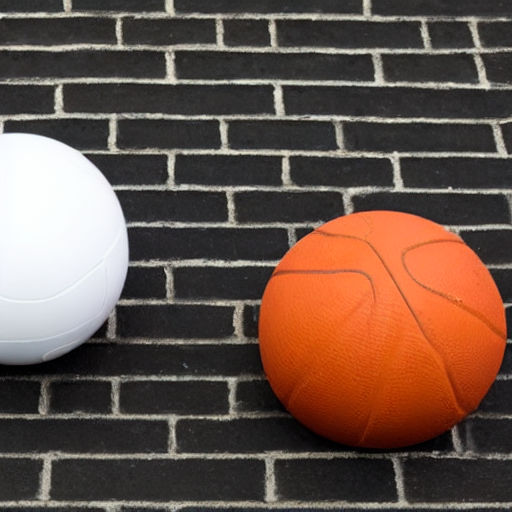

✓ Done
Token indices: [2, 3, 5, 6]
  ✓ Registered 0 attention processors
Generating...


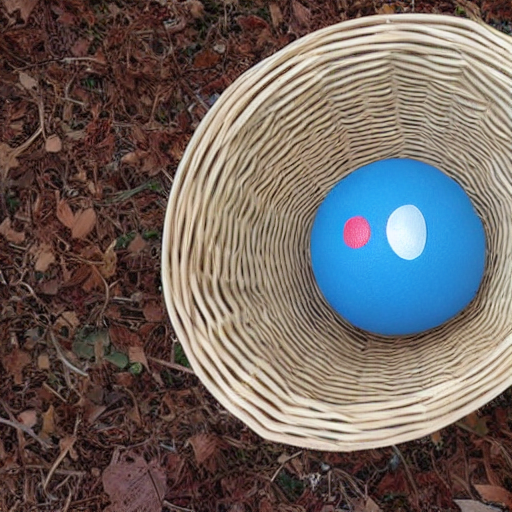

✓ Done
Token indices: [2, 3, 5, 6]
  ✓ Registered 0 attention processors
Generating...


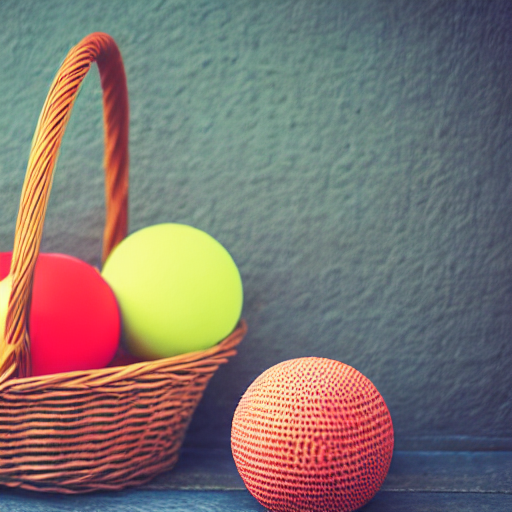

✓ Done

✨ Batch complete. All images saved in: /kaggle/working/attend_Batch


In [6]:
import os
import torch
from pathlib import Path
from IPython.display import display
from diffusers import StableDiffusionXLImg2ImgPipeline

# ===============================
# ENTRY POINT
# ===============================
if __name__ == "__main__":

    # List of prompts to evaluate for compositional logic
    prompts = [
            "A ball roughly next to a basket"
    ]
    
    # Note: Ensure get_token_indices extracts the correct nouns for each prompt
    # Here we define the tracking words per prompt index
    tracking_words = [
        ["ball", "basket"]
    ]

    negative_prompt = (
        "same size object, equal size, merged objects, "
        "single subject, blurry, low quality, cartoon, illustration, "
        "3d render, painting, text, watermark"
    )

    # Generate seeds from 42 to 142 inclusive (101 total)
    seeds = [142,742,842]


    output_root = Path("./attend_Batch")
    output_root.mkdir(exist_ok=True)

    for p_idx, prompt_text in enumerate(prompts):
        # Create a subfolder for each specific prompt to avoid clutter
        prompt_folder_name = prompt_text[:30].replace(" ", "_")
        prompt_path = output_root / f"prompt_{p_idx}_{prompt_folder_name}"
        prompt_path.mkdir(exist_ok=True)
        
        words = tracking_words[p_idx]

        print(f"\n🚀 Processing Prompt {p_idx+1}/{len(prompts)}: {prompt_text}")

        for seed_value in seeds:
            print(f"Generating Seed: {seed_value}...", end="\r")

            # ===============================
            # Stage 1 — FUZZY GENERATION
            # ===============================
            image = generate_image(prompt=prompt_text, seed=seed_value, negative_prompt=negative_prompt, token_indices=[2,3,5,6])

            if image is None:
                continue

            # Save Stage-1 image
            s1_filename = f"seed_{seed_value}_stage1.png"
            image.save(prompt_path / s1_filename)


    print(f"\n✨ Batch complete. All images saved in: {output_root.absolute()}")